# 🌍 Real-World Time Series Forecasting: Predicting Electricity Demand

## 🎯 Scenario

You’re a data scientist at **GreenGrid Analytics**, a startup that helps renewable energy providers forecast electricity demand across the U.S. East Coast. Your client, a solar-wind hybrid farm, must submit **hourly load forecasts** to the PJM Interconnection grid operator 24 hours in advance.

Why does this matter?
- **Over-predict** → waste battery storage
- **Under-predict** → buy expensive fossil-fuel power at the last minute

Your mission: Build a **robust, interpretable forecasting model** using real historical data—and validate it with **realistic backtesting**.

In this notebook, you’ll:
1. Download real PJM hourly load data from Google Drive
2. Engineer smart features (lags, rolling stats, cyclic time)
3. Train an XGBoost model
4. Evaluate performance using **walk-forward backtesting**

> 💡 This mirrors industry best practices—no data leakage, no future peeking!

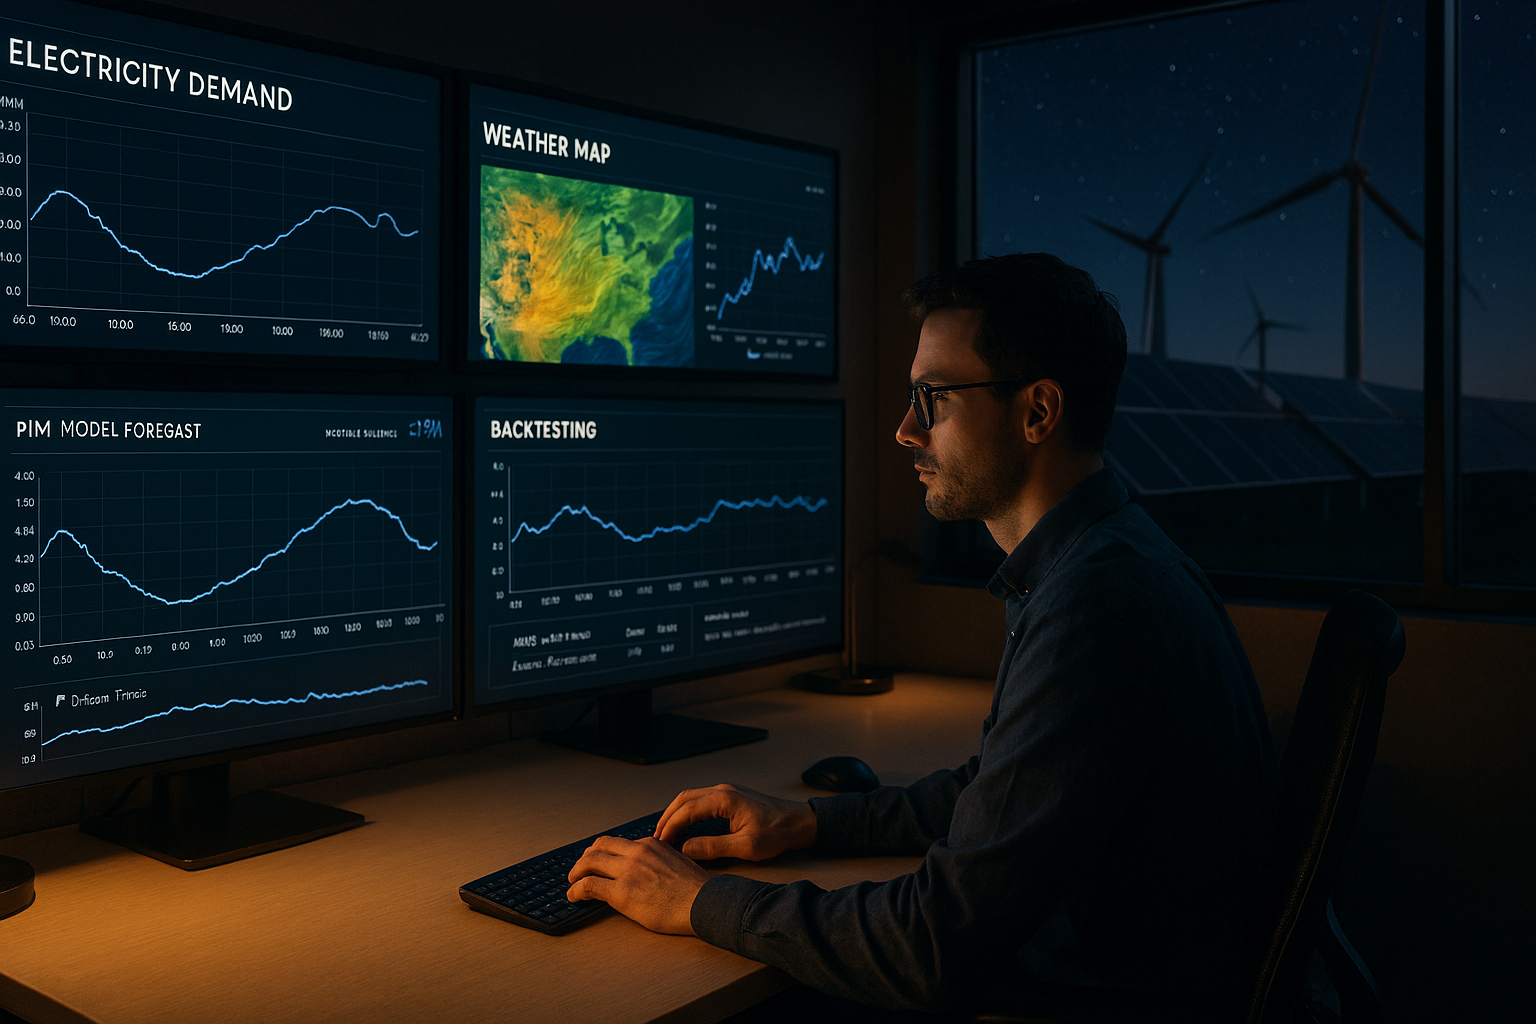

In [ ]:
# Step 1: Install required packages
!pip install gdown xgboost scikit-learn matplotlib pandas numpy

## 📥 Step 2: Download Dataset from Google Drive

We use `gdown` to fetch the dataset using the file ID from your shared link:
- File ID: `1b4B7apaci3d5sa0fsgN-qCr_WDiq6p0S`
- Contains: `PJM_Load_hourly.csv` (hourly electricity demand in MW)

In [ ]:
# Download and unzip dataset from Google Drive
file_id = "1b4B7apaci3d5sa0fsgN-qCr_WDiq6p0S"
!gdown {file_id} -O PJM.zip
!unzip -q PJM.zip

# Verify file
!ls -l PJM_Load_hourly.csv

Downloading...
From: https://drive.google.com/uc?id=1b4B7apaci3d5sa0fsgN-qCr_WDiq6p0S
To: /content/PJM.zip
100% 12.0M/12.0M [00:00<00:00, 112MB/s] 
replace AEP_hourly.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
-rw-r--r-- 1 root root 921109 Oct  4  2019 PJM_Load_hourly.csv


## 📊 Step 3A: Load and Inspect Data

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('PJM_Load_hourly.csv', parse_dates=['Datetime'])

# Set datetime as index and sort
df.set_index('Datetime', inplace=True)
df.sort_index(inplace=True)

# Optional: Use only recent data to speed up (e.g., last 2 years)
# df = df.last('730D')

print(f"Dataset loaded: {len(df)} hourly records from {df.index.min()} to {df.index.max()}")
df.head()

Dataset loaded: 32896 hourly records from 1998-04-01 01:00:00 to 2002-01-01 00:00:00


,PJM_Load_MW
Datetime,
1998-04-01 01:00:00,22259.0
1998-04-01 02:00:00,21244.0
1998-04-01 03:00:00,20651.0
1998-04-01 04:00:00,20421.0
1998-04-01 05:00:00,20713.0


## 🔍 Step 3B: Exploratory Data Analysis (EDA)

Before modeling, we explore the data to:
- Understand **scale, trends, and seasonality**
- Detect **anomalies or missing periods**
- Inform **feature engineering and model design**

### Key Questions We’ll Answer:
1. **What’s the overall trend?** (e.g., growing demand over years?)
2. **Is there daily/weekly seasonality?** (e.g., higher demand at 6 PM, lower on weekends?)
3. **Are there outliers or data gaps?**

> 💡 Time series EDA is visual! We’ll use line plots, histograms, and seasonal summaries.

/tmp/ipython-input-759388603.py:11: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  df['PJM_Load_MW'].last('90D').plot(title='Hourly Electricity Demand (Last 90 Days)', color='tab:blue')


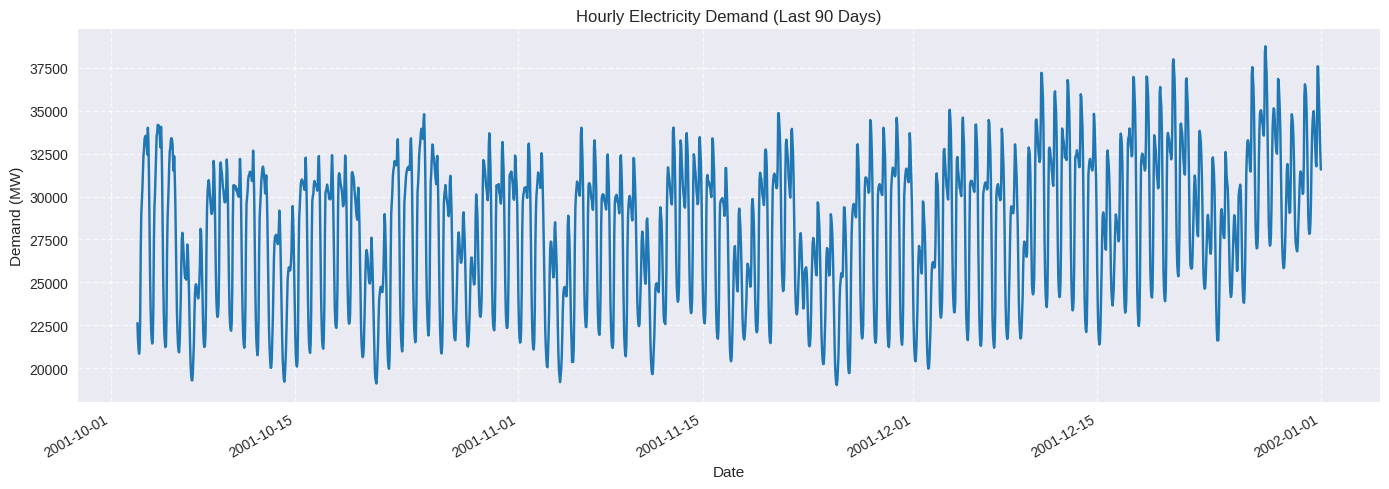

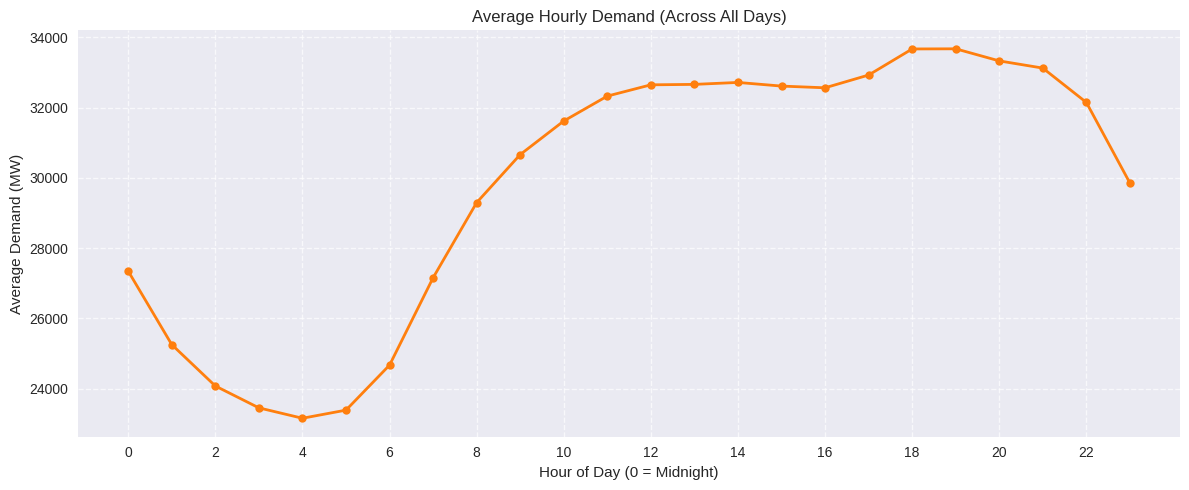

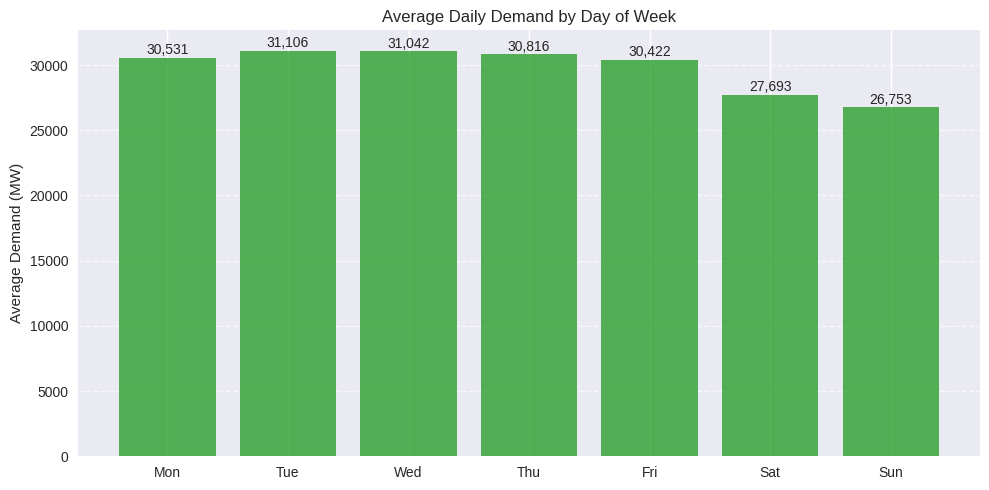

📊 Data Completeness Report:
- Total records: 32,896
- Date range: 1998-04-01 to 2002-01-01
- Expected hours in range: 32,904
- Missing hours: 8 (0.02%)


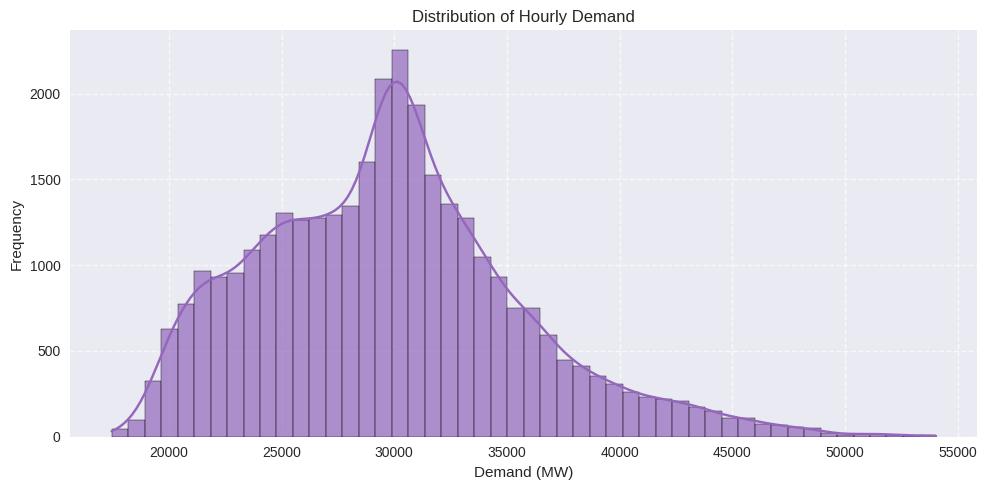

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set style for better-looking plots
plt.style.use('seaborn-v0_8')

# 1. Overall time series plot (last 90 days for clarity)
plt.figure(figsize=(14, 5))
df['PJM_Load_MW'].last('90D').plot(title='Hourly Electricity Demand (Last 90 Days)', color='tab:blue')
plt.ylabel('Demand (MW)')
plt.xlabel('Date')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Daily seasonality: average demand by hour of day
plt.figure(figsize=(12, 5))
hourly_avg = df.groupby(df.index.hour)['PJM_Load_MW'].mean()
plt.plot(hourly_avg.index, hourly_avg.values, marker='o', linewidth=2, markersize=6, color='tab:orange')
plt.title('Average Hourly Demand (Across All Days)')
plt.xlabel('Hour of Day (0 = Midnight)')
plt.ylabel('Average Demand (MW)')
plt.xticks(range(0, 24, 2))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Weekly seasonality: average demand by day of week
plt.figure(figsize=(10, 5))
daily_avg = df.groupby(df.index.dayofweek)['PJM_Load_MW'].mean()
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
bars = plt.bar(days, daily_avg.values, color='tab:green', alpha=0.8)
plt.title('Average Daily Demand by Day of Week')
plt.ylabel('Average Demand (MW)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
# Add value labels on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{int(yval):,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

# 4. Check for missing data
total_records = len(df)
date_range = df.index.max() - df.index.min()
expected_hours = int(date_range.total_seconds() / 3600) + 1
missing_hours = expected_hours - total_records

print("📊 Data Completeness Report:")
print(f"- Total records: {total_records:,}")
print(f"- Date range: {df.index.min().date()} to {df.index.max().date()}")
print(f"- Expected hours in range: {expected_hours:,}")
print(f"- Missing hours: {missing_hours:,} ({missing_hours / expected_hours:.2%})")

# 5. Distribution of demand values
plt.figure(figsize=(10, 5))
sns.histplot(df['PJM_Load_MW'], kde=True, bins=50, color='tab:purple', alpha=0.7)
plt.title('Distribution of Hourly Demand')
plt.xlabel('Demand (MW)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 📌 What This EDA Reveals

1. **Overall Trend & Volatility**  
   The first plot (last 90 days) shows that electricity demand is **not random**—it has clear peaks and troughs. You’ll likely see higher demand during weekdays and summer months (due to air conditioning).

2. **Daily Seasonality**  
   The hourly average plot typically shows a **double-peak pattern**:  
   - Morning peak (~8 AM): people start work, turn on devices  
   - Evening peak (~6–7 PM): cooking, lighting, heating/cooling  
   This confirms that **hour of day is a critical feature**.

3. **Weekly Seasonality**  
   The bar chart usually shows **lower demand on weekends** (Saturday/Sunday), especially compared to weekdays. This validates using `day_of_week` as a feature.

4. **Data Completeness**  
   The missing hours check tells you if the dataset has gaps. Real-world data often has missing values due to sensor errors or reporting delays. If missing hours > 0, you may need interpolation or gap-filling.

5. **Demand Distribution**  
   The histogram shows whether demand is normally distributed or skewed. Electricity demand is often **right-skewed** (rare extreme peaks), which can affect model choice and error metrics.

> 💡 **Key Insight**: Time series like this are **deterministic in pattern but stochastic in magnitude**—the *shape* repeats, but exact values vary. Your model should capture both!

## ⚙️ Step 4: Feature Engineering with Cyclic Encoding

### Why Cyclic Encoding?
Raw `hour` (0–23) treats 23 and 0 as far apart—but they’re adjacent! Sine + cosine maps time onto a circle, preserving continuity.

We create:
- **Lag features**: past demand values
- **Rolling stats**: recent average demand
- **Cyclic time features**: hour and day-of-week as (sin, cos) pairs

In [ ]:
import numpy as np

# Lag features: past values as predictors
df['lag_1'] = df['PJM_Load_MW'].shift(1)        # 1 hour ago
df['lag_24'] = df['PJM_Load_MW'].shift(24)      # 24 hours ago (daily pattern)

# Rolling window: recent average demand
df['rolling_mean_24'] = df['PJM_Load_MW'].rolling(window=24).mean().shift(1)

# Extract raw time components
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek  # Monday=0, Sunday=6

# Cyclic encoding: transform hour and day into (sin, cos) pairs
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['day_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['day_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

# Remove raw cyclic columns (optional, but cleaner)
df.drop(columns=['hour', 'day_of_week'], inplace=True)

# Remove rows with NaN (caused by shifting/rolling)
df.dropna(inplace=True)

print(f"Dataset shape after feature engineering: {df.shape}")

Dataset shape after feature engineering: (32872, 8)


## 🔁 Step 5: Walk-Forward Backtesting – Simulating Real-World Forecasting

In time series forecasting, **how you evaluate your model is just as important as the model itself**. A single train/test split can be misleading because:

- It assumes performance is stable over time (it’s often not!)
- It doesn’t reflect how models are used in production (where you retrain as new data arrives)

### 🎯 What Is Walk-Forward Backtesting?

**Walk-forward backtesting** (also called *rolling forecast origin*) mimics real-world deployment:

1. Start with an initial training window (e.g., first 30 days of data)
2. Train a model on that window
3. Predict the **next time step** (e.g., hour +1)
4. **Move the window forward** by one or more steps
5. Repeat until you’ve covered the entire test period

This gives you **many forecasts over time**, not just one snapshot.

> 💡 Think of it like a time traveler who only knows the past and must predict the immediate future—over and over again.

---

### 🔍 Why This Matters for Electricity Demand

Electricity demand changes with:
- Seasons (summer vs. winter)
- Holidays (Thanksgiving = low demand)
- Extreme weather (heatwaves = spikes)

A model trained only on summer data might fail in winter. Walk-forward validation **exposes these weaknesses** by testing performance across all conditions.

---

### ⚙️ How We Implement It

#### Key Parameters:
- `initial_train_hours = 30 * 24`  
  → Start with 30 days of hourly data to train the first model.
- `step_size = 24`  
  → Retrain the model **once per day** (every 24 hours).  
  → *Why not every hour?* To balance realism and computational cost.

#### The Loop Logic:
```python
for i in range(initial_train_hours, len(df), step_size):
    # Train on df.iloc[:i]      → all data up to "now"
    # Test on df.iloc[i:i+1]    → predict the next hour
    # At each step, the model only sees historical data—no future leakage!
    # We record every prediction and its error to compute robust metrics.
```
### 📊 What We Measure
- Mean Absolute Error (MAE) over all forecast steps  
→ Gives average error in MW, which is interpretable by engineers.
- Error distribution over time  
→ Are errors larger in summer? On weekends? During storms?
This is far more informative than a single MAE from a static split.

---
###💡 Pro Tips
1. Retraining Frequency:
>- Retrain daily (step_size=24) for hourly data → good balance
>- Retrain weekly for daily data
1. Computational Cost:
>- Training a model at every step is expensive
>- In practice, many teams retrain weekly but predict daily/hourly
1. Baseline Comparison:  
Always compare against a naive baseline (e.g., “predict yesterday’s value”) to ensure your model adds real value.
>✅ Golden Rule: If your model doesn’t beat a simple baseline in backtesting, it’s not ready for production.


In [ ]:
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

# Define backtesting parameters
initial_train_hours = 30 * 24  # Start with 30 days of data
step_size = 24                # Retrain every 24 hours (once per day)

# Prepare feature matrix and target
feature_cols = ['lag_1', 'lag_24', 'rolling_mean_24', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']
X = df[feature_cols]
y = df['PJM_Load_MW']

# Storage for results
errors = []
predictions = []
actuals = []
dates = []

# Walk-forward loop
for i in range(initial_train_hours, len(df), step_size):
    # Define train window (all data up to current time)
    X_train = X.iloc[:i]
    y_train = y.iloc[:i]

    # Test point: next hour
    X_test = X.iloc[i:i+1]
    y_test = y.iloc[i:i+1]

    # Skip if test set is empty
    if len(X_test) == 0:
        break

    # Train model
    model = xgb.XGBRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train, verbose=False)

    # Predict
    pred = model.predict(X_test)[0]
    actual = y_test.values[0]

    # Record results
    errors.append(abs(pred - actual))
    predictions.append(pred)
    actuals.append(actual)
    dates.append(y_test.index[0])

print(f"Backtesting completed over {len(errors)} forecast steps.")

Backtesting completed over 1340 forecast steps.


## 📈 Step 6: Evaluate and Visualize Results

✅ Backtested MAE: 297.80 MW


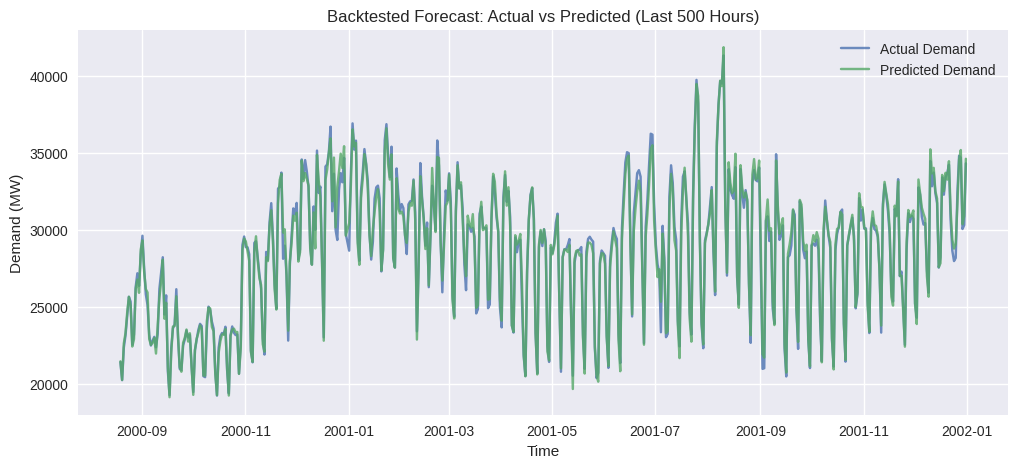

In [ ]:
import matplotlib.pyplot as plt

# Compute overall MAE
mae = np.mean(errors)
print(f"✅ Backtested MAE: {mae:.2f} MW")

# Plot last 500 predictions
plt.figure(figsize=(12, 5))
plt.plot(dates[-500:], actuals[-500:], label='Actual Demand', alpha=0.8)
plt.plot(dates[-500:], predictions[-500:], label='Predicted Demand', alpha=0.8)
plt.title('Backtested Forecast: Actual vs Predicted (Last 500 Hours)')
plt.xlabel('Time')
plt.ylabel('Demand (MW)')
plt.legend()
plt.grid(True)
plt.show()

## 🎯 Key Takeaways

1. **Cyclic encoding** (sin + cos) is essential for time-of-day and day-of-week features—it preserves continuity.
2. **Backtesting** gives realistic performance—far better than a single train/test split.
3. **Lag + rolling features + calendar info** often outperform deep learning on tabular time series.
4. Always **avoid future leakage**: never use data from the future to predict the past!

💡 Next steps:
- Add holiday indicators
- Compare with a naive baseline (e.g., predict `lag_1`)
- Try multi-step forecasting (predict next 24 hours at once)

In [ ]:
import ipywidgets as widgets
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 🔧 Rebuild features (ensure consistency)
def rebuild_features(df_raw):
    df = df_raw.copy()
    df['lag_1'] = df['PJM_Load_MW'].shift(1)
    df['lag_24'] = df['PJM_Load_MW'].shift(24)
    df['rolling_mean_24'] = df['PJM_Load_MW'].rolling(24).mean().shift(1)
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.dayofweek
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    df['day_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
    df['day_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)
    df.drop(columns=['hour', 'day_of_week'], inplace=True, errors='ignore')
    df.dropna(inplace=True)
    return df

# 📦 Validate features
required_cols = ['lag_1', 'lag_24', 'rolling_mean_24', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']
if not all(col in df.columns for col in required_cols):
    df = rebuild_features(df[['PJM_Load_MW']].copy())
feature_cols = required_cols

# 🧠 Forecast with progress
def make_multi_step_forecast(model, df, feature_cols, steps=1, progress_callback=None):
    current_df = df.copy()
    predictions = []
    for i in range(steps):
        latest = current_df.iloc[[-1]]
        X_input = latest[feature_cols]
        pred = model.predict(X_input)[0]
        predictions.append(pred)
        next_time = latest.index[-1] + pd.Timedelta(hours=1)
        new_row = pd.DataFrame({'PJM_Load_MW': [pred]}, index=[next_time])
        current_df = pd.concat([current_df, new_row])
        current_df = rebuild_features(current_df[['PJM_Load_MW']])
        if progress_callback:
            progress_callback(i + 1, steps)
    forecast_index = pd.date_range(start=df.index[-1] + pd.Timedelta(hours=1), periods=steps, freq='h')
    return pd.Series(predictions, index=forecast_index)

# 📅 Format labels
def format_date_with_dow(timestamps):
    return [f"{ts.strftime('%a')}, {ts.strftime('%m-%d %H:%M')}" for ts in timestamps]

# 🎨 Day colors
DAY_COLORS = {
    'Mon': 'steelblue', 'Tue': 'lightgreen', 'Wed': 'gold',
    'Thu': 'orange', 'Fri': 'crimson', 'Sat': 'purple', 'Sun': 'darkred'
}

# 🖼️ Plot function
output_area = widgets.Output()
start_label = widgets.HTML(value="")
duration_slider = widgets.SelectionSlider(
    options=[('1 hour', 1), ('24 hours', 24), ('168 hours (7 days)', 168)],
    value=1,
    description='Duration:',
    continuous_update=False,
    layout=widgets.Layout(width='400px')
)
status_label = widgets.Label(value="Click 'Run Forecast' to begin.")
progress_bar = widgets.IntProgress(value=0, min=0, max=100, description='Progress:', visible=False)

def update_progress(current, total):
    progress_bar.value = int(100 * current / total)

def run_forecast(_):
    start_time = df.index[-1] + pd.Timedelta(hours=1)
    horizon = duration_slider.value

    # Update UI
    start_label.value = f"<b>Forecast Start:</b> {start_time.strftime('%Y-%m-%d %H:%M')} ({start_time.strftime('%A')})"
    status_label.value = f"Generating {horizon}-hour forecast..."
    progress_bar.visible = True
    output_area.clear_output(wait=True)

    try:
        with output_area:
            forecast = make_multi_step_forecast(
                model, df, feature_cols,
                steps=horizon,
                progress_callback=update_progress
            )
            actuals = df['PJM_Load_MW'].reindex(forecast.index)

            plt.figure(figsize=(12, 5))
            plt.plot(forecast.index, forecast.values, label='Predicted', marker='o', color='tab:orange')

            if actuals.notna().any():
                plt.plot(actuals.index, actuals.values, label='Actual', marker='x', color='tab:blue')
                mae = np.mean(np.abs(forecast - actuals.dropna()))
                plt.title(f'Forecast vs Actual (Horizon: {horizon} hour(s) | MAE: {mae:.2f} MW)')
            else:
                plt.title(f'Forecast: Next {horizon} Hour(s)')

            # X-axis with day labels
            all_times = forecast.index
            if actuals.notna().any():
                all_times = all_times.union(actuals.dropna().index)

            max_labels = 12
            if len(all_times) > max_labels:
                step = len(all_times) // max_labels
                tick_times = [all_times[i] for i in range(0, len(all_times), max(1, step))]
            else:
                tick_times = all_times

            plt.xticks(
                ticks=tick_times,
                labels=format_date_with_dow(tick_times),
                rotation=45,
                ha='right'
            )

            # 🌈 Colored vertical lines per day
            for t in tick_times:
                day_abbr = t.strftime('%a')
                color = DAY_COLORS.get(day_abbr, 'gray')
                plt.axvline(x=t, color=color, linestyle='--', alpha=0.4, linewidth=1.2)

            plt.xlabel('Time (Day, Month-Day Hour:Minute)')
            plt.ylabel('Demand (MW)')
            plt.legend()
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.tight_layout()
            plt.show()

            status_label.value = "✅ Forecast complete!"

    except Exception as e:
        with output_area:
            print(f"❌ Error: {e}")
        status_label.value = "⚠️ Forecast failed."
    finally:
        progress_bar.visible = False

# 🧩 Assemble UI
run_button = widgets.Button(description="Run Forecast", button_style='info')
run_button.on_click(run_forecast)

ui = widgets.VBox([
    widgets.HTML("<h3>Custom Forecast Generator</h3>"),
    start_label,
    duration_slider,
    run_button,
    status_label,
    progress_bar,
    output_area
])

display(ui)